In [1]:
PROJECT_RANDOM_STATE = 2627
print("PROJECT_RANDOM_STATE =", PROJECT_RANDOM_STATE)

PROJECT_RANDOM_STATE = 2627


# Practice 3 — Challenge B: linear regression, Ridge and Lasso (storage)

**Team:** Team 1 · **Milestone:** P3

**Roles:** R1 Marina García, R2 Diana Luque, R3 Francisco Moya, R4 Claudia Martínez, R5 Fernando Caceres

Primary metric: **MAE on z = log10(latency_ns)**, on the canonical `storage_folds.csv` assignment. Physical errors are computed after inverting each prediction with `10 ** z_pred`.

# Data and preprocessing (R1)

## Setup

In [2]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# These paths start from the notebooks folder, where this file is run.
FOLDS_DIR = "../folds"

## Data

In [3]:
# This block uses the same names as the cyber block so that the notebooks can be joined.
# R5 copies each challenge into its final notebook, together with the shared setup.
STORAGE_DIR = "../datos/storage"
dev = pd.read_csv(STORAGE_DIR + "/storage_development.csv")
storage_groups = pd.read_csv(STORAGE_DIR + "/storage_groups.csv")
storage_folds = pd.read_csv(FOLDS_DIR + "/storage_folds.csv")

# raid is a nominal label, even though its levels contain numbers.
NOMINAL = ["load_type", "io_type", "raid", "device_type"]
NUMERIC = ["block_size", "n_jobs", "iodepth", "read_fraction", "n_disks"]
FEATURES = NOMINAL + NUMERIC

# The CSV lists the columns in a different order, so we compare the sorted names.
expected_columns = ["row_id"] + FEATURES + ["latency_ns"]
assert sorted(dev.columns) == sorted(expected_columns), "Unexpected storage schema"
assert "iops" not in dev.columns, "Excluded column iops must not be present"
X = dev[FEATURES].copy()
latency_ns = dev["latency_ns"].copy()

# The target must be finite and positive before taking the logarithm.
assert not dev.isna().any().any(), "Missing values in development data"
assert np.isfinite(X[NUMERIC].to_numpy()).all(), "Non-finite numeric predictors"
assert np.isfinite(latency_ns).all(), "Non-finite target values"
assert (latency_ns > 0).all(), "Latency must be strictly positive"
z = np.log10(latency_ns)

for column in ["row_id", "config_group", "feature_group", "fold_id", "latency_ns", "iops"]:
    assert column not in X.columns, "Forbidden predictor: " + column
assert X.shape[1] == 9, "Expected nine source predictors"

print("Development table:", dev.shape)
print("Predictors:", X.shape)
print("Target: z = log10(latency_ns)")
print("Schema, predictor and target checks passed.")

Development table: (12190, 11)
Predictors: (12190, 9)
Target: z = log10(latency_ns)
Schema, predictor and target checks passed.


In [4]:
# As in cyber, we check the row order before using positional indices.
assert list(storage_groups.columns) == ["row_id", "config_group"], "Unexpected group schema"
assert list(storage_folds.columns) == ["row_id", "fold_id"], "Unexpected fold schema"
assert dev["row_id"].is_unique, "Duplicate development row_id"
assert storage_groups["row_id"].is_unique, "Duplicate group row_id"
assert storage_folds["row_id"].is_unique, "Duplicate fold row_id"
assert not storage_groups.isna().any().any(), "Missing group metadata"
assert not storage_folds.isna().any().any(), "Missing fold metadata"
assert dev["row_id"].equals(storage_groups["row_id"]), "Group rows are not aligned"
assert dev["row_id"].equals(storage_folds["row_id"]), "Fold rows are not aligned"
assert sorted(storage_folds["fold_id"].unique()) == [0, 1, 2, 3, 4], "Expected five folds"

print("Row identifiers are unique and aligned across all three tables.")
print("Configuration groups:", storage_groups["config_group"].nunique())

Row identifiers are unique and aligned across all three tables.
Configuration groups: 2438


In [5]:
# We keep the canonical assignment; we do not build a new GroupKFold.
folds = []
fold_rows = []
for fold_id in range(5):
    train_idx = np.flatnonzero(storage_folds["fold_id"].to_numpy() != fold_id)
    val_idx = np.flatnonzero(storage_folds["fold_id"].to_numpy() == fold_id)

    # The replicates of a configuration must always stay together.
    train_groups = set(storage_groups.iloc[train_idx]["config_group"])
    val_groups = set(storage_groups.iloc[val_idx]["config_group"])
    assert train_groups.isdisjoint(val_groups), "Group leakage in fold " + str(fold_id)
    assert len(train_idx) + len(val_idx) == len(dev), "Incomplete partition"

    folds.append((train_idx, val_idx))
    fold_rows.append({"fold_id": fold_id, "training_rows": len(train_idx),
                      "validation_rows": len(val_idx)})

print(pd.DataFrame(fold_rows).to_string(index=False))
print("All five canonical folds passed the group separation checks.")

 fold_id  training_rows  validation_rows
       0           9750             2440
       1           9750             2440
       2           9750             2440
       3           9755             2435
       4           9755             2435
All five canonical folds passed the group separation checks.


The storage development table contains 12,190 rows and nine source predictors: four nominal and five numeric. There are 2,438 configuration groups. Identifiers, grouping metadata, fold assignments and the target are excluded from `X`; `iops` is absent. The canonical assignments keep configurations separate between training and validation.

The target is `z = log10(latency_ns)`, as fixed in P2. The original `latency_ns` values are retained for physical-scale evaluation. R3 must compute predictions in nanoseconds as `10 ** z_hat` before calculating physical errors. Exponentiating a log-scale error does not produce an error in nanoseconds.

## Declared reference levels (statement, Sections 1.1 and 2)

In [6]:
# The order matches NOMINAL: load_type, io_type, raid and device_type.
# We use the most frequent level of each predictor as its fixed reference.
REFERENCE_LEVELS = ["random", "write", "4+1", "nvme"]

reference_rows = []
for column, reference in zip(NOMINAL, REFERENCE_LEVELS):
    row = {"predictor": column, "reference": reference}
    for fold_id, (train_idx, val_idx) in enumerate(folds):
        # Each reference must appear in all five training portions.
        training_count = int((X.iloc[train_idx][column] == reference).sum())
        assert training_count > 0, "Reference missing from training: " + column
        row["training_count_fold_" + str(fold_id)] = training_count
    reference_rows.append(row)

print(pd.DataFrame(reference_rows).to_string(index=False))

  predictor reference  training_count_fold_0  training_count_fold_1  training_count_fold_2  training_count_fold_3  training_count_fold_4
  load_type    random                   6465                   6465                   6450                   6480                   6480
    io_type     write                   5665                   5665                   5620                   5650                   5720
       raid       4+1                   4310                   4400                   4395                   4345                   4350
device_type      nvme                   8125                   8105                   8085                   8120                   8125


**Reference levels and their reasons.** In the order of `NOMINAL`, the declared
references are `load_type=random`, `io_type=write`, `raid=4+1` and
`device_type=nvme`. Each is the most frequent level of its predictor in the
development table and is present in all five training portions, as checked
above. They are fixed baselines for interpretation, not choices selected by
validation scores. Each remaining indicator contrasts its level with the
reference of the same predictor. In particular, RAID schemes are nominal
labels; they are not ordered numbers.

**Unseen-level policy.** `handle_unknown="ignore"` encodes an unseen level as
zeros for that predictor. With the reference indicator dropped, this treats it
as the declared reference. It is a fallback rule, not an assertion that the
levels are equivalent. The vocabulary is learned only from the training rows
of each fold, just as in cyber.

## Preprocessing block (publish for R3 and R4)

In [7]:
def make_preprocessor():
    # Same ColumnTransformer as in notebook 02, adapted to the storage columns.
    # We drop one reference category per nominal predictor, as P3 requires.
    nominal_steps = OneHotEncoder(
        drop=REFERENCE_LEVELS,
        handle_unknown="ignore",
        sparse_output=False,
    )

    # In storage the original values are standardised, with no log1p on X.
    numeric_steps = StandardScaler()

    preprocessor = ColumnTransformer([
        ("nominal", nominal_steps, NOMINAL),
        ("numeric", numeric_steps, NUMERIC),
    ])
    # R3/R4 must place this unfitted object inside the Pipeline of each model.
    return preprocessor

**Scaling decision.** The five numeric predictors use `StandardScaler`, fitted
only on the training rows of each canonical fold. A one-unit increase in a
transformed numeric predictor means one training standard deviation in that
original predictor, with the other inputs held fixed. No `log1p` predictor
transformation is introduced for storage. The target transformation
`z = log10(latency_ns)` is separate from this preprocessor.

The nominal predictors use one-hot encoding with a declared reference removed;
their indicators remain 0/1. No imputation is added because the data checks
confirm there are no missing values. Numeric coefficients share a common
standardised scale and can be compared within that group. Categorical
coefficients describe contrasts with their own references; their magnitudes
must not be ranked against numeric coefficients.

`make_preprocessor()` returns a fresh, unfitted transformer. R3/R4 must place
it inside each model's `Pipeline`, so the encoder vocabulary and scaler state
are learned only from that fold's training portion. Validation uses the same
fitted state without refitting. The unregularised, Ridge and Lasso models must
use this same representation.

In [8]:
# Block check: each fold starts with a fresh preprocessor.
preprocessing_rows = []
for fold_id, (train_idx, val_idx) in enumerate(folds):
    preprocessor = make_preprocessor()
    assert not hasattr(preprocessor, "transformers_"), "Expected an unfitted transformer"
    X_train = X.iloc[train_idx]
    X_valid = X.iloc[val_idx]
    X_train_transformed = preprocessor.fit_transform(X_train)
    X_valid_transformed = preprocessor.transform(X_valid)

    # As in notebook 02, we inspect what each block has learned.
    encoder = preprocessor.named_transformers_["nominal"]
    scaler = preprocessor.named_transformers_["numeric"]
    training_numeric = X_train[NUMERIC].to_numpy()
    assert np.allclose(scaler.mean_, training_numeric.mean(axis=0)), "Wrong scaler mean"
    assert np.allclose(scaler.scale_, training_numeric.std(axis=0)), "Wrong scaler scale"
    for column, categories, dropped in zip(NOMINAL, encoder.categories_, encoder.drop_idx_):
        assert list(categories) == sorted(X_train[column].unique()), "Wrong vocabulary"
        position = NOMINAL.index(column)
        assert categories[dropped] == REFERENCE_LEVELS[position], "Wrong dropped level"

    # Validation uses transform, never fit: it keeps the training columns.
    feature_names = preprocessor.get_feature_names_out()
    assert X_train_transformed.shape[1] == len(feature_names), "Missing feature names"
    assert X_valid_transformed.shape[1] == len(feature_names), "Inconsistent columns"
    assert np.isfinite(X_train_transformed).all(), "Non-finite training values"
    assert np.isfinite(X_valid_transformed).all(), "Non-finite validation values"
    preprocessing_rows.append({"fold_id": fold_id, "output_features": len(feature_names),
                               "training_state_verified": True})

print(pd.DataFrame(preprocessing_rows).to_string(index=False))
print("Transformed feature names (last fold):", list(feature_names))

 fold_id  output_features  training_state_verified
       0               13                     True
       1               13                     True
       2               13                     True
       3               13                     True
       4               13                     True
Transformed feature names (last fold): ['nominal__load_type_sequential', 'nominal__io_type_read', 'nominal__raid_1+1', 'nominal__raid_2+1', 'nominal__raid_2+2', 'nominal__raid_4+2', 'nominal__raid_8+2', 'nominal__device_type_hdd', 'numeric__block_size', 'numeric__n_jobs', 'numeric__iodepth', 'numeric__read_fraction', 'numeric__n_disks']


In [9]:
# We check the target representation and its return to the physical scale.
assert np.isfinite(z).all(), "Non-finite log target"
assert np.allclose(10 ** z, latency_ns), "Target inversion does not recover latency"
print("Target check passed: 10 ** z recovers latency_ns.")

Target check passed: 10 ** z recovers latency_ns.


The preprocessing checks pass on all five canonical folds. Each fitted scaler matches the means and standard deviations of its own training rows, and each encoder vocabulary matches the categories in those rows. The declared reference indicators are removed. Training and validation matrices are finite and have the same 13 output columns in every fold (8 categorical indicators and 5 numeric predictors).

The target inversion check confirms that `10 ** z` recovers the original `latency_ns`. This verifies the representation, not predictive performance. R3 must still invert its model predictions before computing physical-scale errors.

## `features.md`

The dated Practice 3 entry is recorded in `../plantillas/features.md`. It preserves the P2 entries and documents the declared references, encoding policy, retained numeric transformations and unchanged predictive-information basis.

# Canonical folds and evaluation (R4)

## Setup and shared helpers

In [10]:
# Standard library: read the JSON file with the class names
import json

# Numerical arrays and tables
import numpy as np
import pandas as pd

# scikit-learn: baselines, metrics and out-of-fold predictions
import sklearn
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_recall_fscore_support, r2_score)
from sklearn.model_selection import cross_val_predict

# Library versions: some results can change from one version to another
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.5.4
pandas       3.0.1
scikit-learn 1.9.1


### Shared helpers (used by both challenges)

These functions are used in the cyber and in the storage part, so this cell goes into
both final notebooks.

- `canonical_cv` reads the course fold file and returns `folds`, the list of
  `(train_idx, val_idx)` pairs. The folds are read, never rebuilt. As in Practice 2, all the
  folds go through this one function.
- `check_folds` checks the grouping rule: in every fold, no group is both in training and in
  validation, and every row is validated exactly once.
- `mean_and_spread` gives the mean and the spread (max − min) of the five fold values, the
  same definition used in `comparativa.csv`.

In [11]:
# K, the number of canonical folds
CV_FOLDS = 5


# Read the canonical folds of one challenge ("cyber" or "storage") from the course file
def canonical_cv(challenge, dev):
    """Read the course fold file and return the folds as (train_idx, val_idx) pairs."""
    # The course file has two columns: row_id and fold_id (0 to 4)
    fold_table = pd.read_csv("../folds/" + challenge + "_folds.csv")

    # The positions only make sense if both files list the rows in the same order
    same_order = np.array_equal(fold_table["row_id"].to_numpy(), dev["row_id"].to_numpy())
    assert same_order, "the fold file and the data table list the rows in a different order"

    # Fold number of each row, as a NumPy array
    fold_id = fold_table["fold_id"].to_numpy()

    # One (train_idx, val_idx) pair per fold
    folds = []
    for f in range(CV_FOLDS):
        train_idx = np.where(fold_id != f)[0]   # positions of the rows of the other four folds
        val_idx = np.where(fold_id == f)[0]     # positions of the rows of fold f
        folds.append((train_idx, val_idx))
    return folds

In [12]:
# Check the grouping rule of the canonical folds and print the size of each fold
def check_folds(folds, groups):
    """Check that no group is split between training and validation, fold by fold."""
    # Group of each row (feature_group in cyber, config_group in storage)
    groups = np.asarray(groups)
    # How many times each row appears in a validation part; it must end at 1
    times_validated = np.zeros(len(groups), dtype=int)

    for number, (train_idx, val_idx) in enumerate(folds, start=1):
        # Groups that appear both in the training part and in the validation part
        shared = set(groups[train_idx]) & set(groups[val_idx])
        print(f"fold {number}: {len(train_idx)} training rows, {len(val_idx)} validation rows, "
              f"{len(shared)} groups in both parts")
        # Stop the notebook if any group is split between the two parts
        assert len(shared) == 0, "a group is in training and in validation"
        # Count one more validation for the rows of this fold
        times_validated[val_idx] = times_validated[val_idx] + 1

    # Every row must be in the validation part of exactly one fold
    assert (times_validated == 1).all(), "a row is not validated exactly once"
    print("every row is validated exactly once")


# Summary of five per-fold values, with the same definition of spread as comparativa.csv
def mean_and_spread(values):
    """Mean and spread (max - min) of the five fold values."""
    values = np.asarray(values, dtype=float)
    return values.mean(), values.max() - values.min()

### Helpers for `comparativa.csv` and the paired differences

- `append_comparativa_row` adds one row at the end of the table. It never rewrites the rows
  that are already there, and it does not add the same row twice if the notebook is run again.
  It is based on the function of R4 in Practice 2.
- `table_scores` reads the five per-fold values of one row of the table.
- `paired_differences` compares two rows fold by fold. The sign follows the statement
  (Practice 2, Section 5.3): a positive difference always means that the new row did better
  on that fold. For macro F1, $\delta_f = \text{new}_f - \text{P2}_f$; for MAE(z), where lower
  is better, $\delta_f = \text{P2}_f - \text{new}_f$.

The differences are computed from the values as written in the table (four decimals), so
anyone can recompute them from `comparativa.csv`.

In [13]:
# The comparison table, in the root of the repository
COMPARISON_PATH = "../comparativa.csv"


# Turn five numbers into the text format of comparativa.csv, e.g. "0.9436 0.9473 ..."
def fold_text(values):
    """Write the five fold values as one text with 4 decimals, as in comparativa.csv."""
    parts = []
    for value in values:
        parts.append(f"{value:.4f}")   # 4 decimals, e.g. 0.9436
    return " ".join(parts)             # joined with spaces


# Add one row at the end of comparativa.csv without touching the rows already there
def append_comparativa_row(row):
    """Add one row at the end of comparativa.csv. The rows already there are never changed."""
    table = pd.read_csv(COMPARISON_PATH)

    # 1. The new row must have exactly the columns of the table, in the same order
    assert list(row.keys()) == list(table.columns), "the row does not have the table columns"

    # 2. If the same row is already in the table (notebook run again), do not add it twice
    same_row = ((table["milestone"] == row["milestone"])
                & (table["challenge"] == row["challenge"])
                & (table["family"] == row["family"])
                & (table["route"] == row["route"]))
    if same_row.any():
        print("already in comparativa.csv:", row["milestone"], row["challenge"], row["family"])
        return

    # 3. mode="a" writes at the end of the file and leaves every earlier line as it was
    pd.DataFrame([row]).to_csv(COMPARISON_PATH, mode="a", header=False, index=False)
    print("added to comparativa.csv:", row["milestone"], row["challenge"], row["family"])

In [14]:
# Read the five per-fold values of the primary metric of one row of comparativa.csv
def table_scores(milestone, challenge, family):
    """Five per-fold values of the primary metric of one row of comparativa.csv."""
    table = pd.read_csv(COMPARISON_PATH)
    # True only for the row with this milestone, challenge and family
    is_row = ((table["milestone"] == milestone)
              & (table["challenge"] == challenge)
              & (table["family"] == family))
    # Stop the notebook if there is no such row, or more than one
    assert is_row.sum() == 1, "expected exactly one row for " + milestone + " " + family
    # The values are stored as one text, e.g. "0.9436 0.9473 ..."
    text = table.loc[is_row, "primary_metric_per_fold"].iloc[0]
    # Split the text at the spaces and turn each part into a number
    return np.array(text.split(), dtype=float)


# Compare a new row with a Practice 2 row fold by fold and print a short summary
def paired_differences(challenge, new_scores, old_scores):
    """delta for each fold; a positive delta always means the new row did better."""
    if challenge == "cyber":
        delta = new_scores - old_scores    # macro F1: higher is better
    else:
        delta = old_scores - new_scores    # MAE(z): lower is better

    # One row per fold: Practice 2 value, new value and their difference
    table = pd.DataFrame({"P2": old_scores, "new": new_scores, "delta": delta},
                         index=range(1, CV_FOLDS + 1))
    table.index.name = "fold"
    print(table.round(4).to_string())

    # Descriptive summary of the five differences (not a statistical test)
    mean_delta, spread_delta = mean_and_spread(delta)
    print(f"mean delta            {mean_delta:+.4f}")
    print(f"spread of delta       {spread_delta:.4f}   (max - min)")
    print(f"folds with delta > 0  {(delta > 0).sum()} of {CV_FOLDS}")
    # Fold-to-fold variability of each row, to judge the size of the change
    print(f"spread of P2 row      {mean_and_spread(old_scores)[1]:.4f}")
    print(f"spread of new row     {mean_and_spread(new_scores)[1]:.4f}")
    return table

**Check of the paired-difference code.** We compare two Practice 2 rows whose differences
Practice 2 already printed: KNN against Dummy in Challenge A, with differences 0.9194,
0.9231, 0.9248, 0.9187 and 0.9209. The values must match up to the four-decimal rounding of
the table (on fold 4 the table gives 0.9186).

In [15]:
# Two Practice 2 rows of comparativa.csv
knn_scores = table_scores("P2", "cyber", "KNN")
dummy_scores = table_scores("P2", "cyber", "Dummy")

# KNN plays the role of the "new" row and Dummy the role of the "old" one
check = paired_differences("cyber", knn_scores, dummy_scores)

# Each table value is rounded to 4 decimals, so a difference can move by 0.0001
printed_in_p2 = [0.9194, 0.9231, 0.9248, 0.9187, 0.9209]
assert np.allclose(check["delta"], printed_in_p2, atol=0.00015)
print("\nthe function gives the differences printed in Practice 2")

          P2     new   delta
fold                        
1     0.0242  0.9436  0.9194
2     0.0242  0.9473  0.9231
3     0.0242  0.9490  0.9248
4     0.0242  0.9428  0.9186
5     0.0242  0.9451  0.9209
mean delta            +0.9214
spread of delta       0.0062   (max - min)
folds with delta > 0  5 of 5
spread of P2 row      0.0000
spread of new row     0.0062

the function gives the differences printed in Practice 2


In [16]:
# R1 names the grouping table storage_groups; the R4 and R3 cells below call it groups
groups = storage_groups

## Canonical folds and metrics (publish for R3)

The folds are read from `folds/storage_folds.csv`, the course file. They come from a
`GroupKFold(5)` on `config_group`, so the five replicates of a configuration always stay in
the same fold.

In [17]:
# The groups file must list the rows in the same order as the data table
assert np.array_equal(groups["row_id"].to_numpy(), dev["row_id"].to_numpy())

# Canonical folds of Challenge B: a list of five (train_idx, val_idx) pairs
folds = canonical_cv("storage", dev)

In [18]:
# Grouping rule: no config_group may be in training and in validation of the same fold
check_folds(folds, groups["config_group"])

# X must only hold the source predictors: never row_id, feature_group, config_group or fold_id
assert list(X.columns) == FEATURES

fold 1: 9750 training rows, 2440 validation rows, 0 groups in both parts
fold 2: 9750 training rows, 2440 validation rows, 0 groups in both parts
fold 3: 9750 training rows, 2440 validation rows, 0 groups in both parts
fold 4: 9755 training rows, 2435 validation rows, 0 groups in both parts
fold 5: 9755 training rows, 2435 validation rows, 0 groups in both parts
every row is validated exactly once


**Metric code for Challenge B** (the metric contract of Practice 2). As in Challenge A, the
model is fitted outside the function, for example with `cross_val_predict(model, X, z, cv=folds)`,
so the prediction of each row comes from a model that did not see it.

- MAE(z) (primary), RMSE(z) and R²(z) are computed from $z$ and $\hat z$.
- MAE in ns is computed only after turning each prediction back into nanoseconds with
  $10^{\hat z}$. Raising 10 to MAE(z) gives a multiplicative factor, never an error in ns.

In [19]:
# Metrics of Challenge B on each fold, from the out-of-fold predictions of z
def storage_fold_metrics(z, z_pred, latency_ns, folds):
    """MAE(z), RMSE(z), R2(z) and MAE in ns on the validation rows of each fold."""
    rows = []
    for number, (train_idx, val_idx) in enumerate(folds, start=1):
        # True and predicted z of the validation rows of this fold
        z_true_fold = z[val_idx]
        z_pred_fold = z_pred[val_idx]
        # Back to nanoseconds: we invert the predictions, never the MAE
        latency_pred_fold = 10 ** z_pred_fold
        # One dictionary per fold: three metrics on z, one metric in nanoseconds
        rows.append({"fold": number,
                     "mae_z": mean_absolute_error(z_true_fold, z_pred_fold),
                     "rmse_z": np.sqrt(mean_squared_error(z_true_fold, z_pred_fold)),
                     "r2_z": r2_score(z_true_fold, z_pred_fold),
                     "mae_ns": mean_absolute_error(latency_ns[val_idx], latency_pred_fold)})
    # Table with one row per fold
    return pd.DataFrame(rows).set_index("fold")

**Check: the folds and the metric code reproduce Practice 2.** We run again the Practice 2
baseline, `DummyRegressor(strategy="mean")` on $z$, and compare its MAE(z) per fold with the
P2 row of `comparativa.csv`.

In [20]:
# Out-of-fold predictions of the Practice 2 baseline (the mean of z) on the canonical folds
z_pred_dummy = cross_val_predict(DummyRegressor(strategy="mean"), X, z, cv=folds)

# Its metrics on each fold
dummy_metrics = storage_fold_metrics(z, z_pred_dummy, latency_ns, folds)
print(dummy_metrics.round(4).to_string())

# MAE(z) must equal the P2 Dummy row of comparativa.csv (rounded to 4 decimals there)
p2_dummy = table_scores("P2", "storage", "Dummy")
assert np.allclose(dummy_metrics["mae_z"], p2_dummy, atol=0.00005)
print("\nMAE(z) per fold equals the P2 Dummy row of comparativa.csv")

       mae_z  rmse_z    r2_z        mae_ns
fold                                      
1     0.6800  0.8445 -0.0002  2.839968e+07
2     0.6778  0.8436 -0.0002  2.854142e+07
3     0.6628  0.8331 -0.0001  2.742680e+07
4     0.6722  0.8269 -0.0001  2.407004e+07
5     0.6922  0.8517 -0.0000  2.674962e+07

MAE(z) per fold equals the P2 Dummy row of comparativa.csv


# P3.3 and P3.4 (R3)

# P3.3 — Linear regression

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [22]:
import time

mae_list = []
rmse_list = []
r2_list = []
mae_ns_list = []
coef_list = []
fit_time_list = []

for train_idx, val_idx in folds:
    # the preprocessor is fitted inside the fold, on training rows only
    model = Pipeline([("prep", make_preprocessor()), ("reg", LinearRegression())]) #declare model with preprocessing function and type (regression)
    start = time.perf_counter() #start the clock
    model.fit(X.iloc[train_idx], z[train_idx]) #train the model
    fit_time_list.append(time.perf_counter() - start) #seconds spent training

    z_pred = model.predict(X.iloc[val_idx]) #obtain the prediction for the validation data
    z_true = z[val_idx] #obtain the validation true values on those same rows

    mae_list.append(mean_absolute_error(z_true, z_pred))
    rmse_list.append(np.sqrt(mean_squared_error(z_true, z_pred)))
    r2_list.append(r2_score(z_true, z_pred))
    # back to nanoseconds first, then the error
    mae_ns_list.append(mean_absolute_error(latency_ns[val_idx], 10 ** z_pred))
    coef_list.append(model.named_steps["reg"].coef_)

In [23]:
print("MAE(z) per fold:", np.round(mae_list, 4))
print("MAE(z) mean:", round(np.mean(mae_list), 4), "range (max - min):", round(np.max(mae_list) - np.min(mae_list), 4))
print("RMSE(z) mean:", round(np.mean(rmse_list), 4))
print("R2(z) mean:", round(np.mean(r2_list), 4))
print("MAE_ns mean:", round(np.mean(mae_ns_list)))
print("Fit time mean (s):", round(np.mean(fit_time_list), 4))

MAE(z) per fold: [0.2047 0.1937 0.1984 0.1953 0.1987]
MAE(z) mean: 0.1981 range (max - min): 0.0111
RMSE(z) mean: 0.2703
R2(z) mean: 0.8964
MAE_ns mean: 16289769
Fit time mean (s): 0.1061


**Interpretation.** 
The mean MAE(z) is 0.1981, so predictions are off by a factor of about 10^0.1981 ≈ 1.58 on a typical row. R²(z) is 0.8964. The MAE of about 16.3 million ns was computed after inverting predictions with 10^z. It is dominated by the slowest configurations, so it does not replace the error on z.

In [24]:
#here we show the coefficients (weight) of each variable in each fold
names = model.named_steps["prep"].get_feature_names_out()
coef_table = pd.DataFrame(coef_list, columns=names)
print(coef_table.T.round(4))
summary = pd.DataFrame({"mean coef": coef_table.mean(), "factor": 10 ** coef_table.mean()})
print(summary.round(4))

                                    0       1       2       3       4
nominal__load_type_sequential  0.5442  0.5667  0.5425  0.5165  0.5466
nominal__io_type_read         -0.1977 -0.1925 -0.1999 -0.2053 -0.1891
nominal__raid_1+1              0.0062  0.0067  0.0001  0.0114  0.0095
nominal__raid_2+1             -0.0613 -0.0645 -0.0606 -0.0520 -0.0675
nominal__raid_2+2             -0.0366 -0.0210 -0.0377 -0.0244 -0.0365
nominal__raid_4+2             -0.0440 -0.0645 -0.0571 -0.0581 -0.0689
nominal__raid_8+2             -0.0220 -0.0156 -0.0067 -0.0053 -0.0227
nominal__device_type_hdd       1.0496  1.0331  1.0453  1.0820  1.0354
numeric__block_size            0.2569  0.2484  0.2585  0.2577  0.2625
numeric__n_jobs                0.2586  0.2552  0.2518  0.2555  0.2566
numeric__iodepth               0.2653  0.2655  0.2633  0.2570  0.2677
numeric__read_fraction        -0.0570 -0.0542 -0.0571 -0.0613 -0.0545
numeric__n_disks              -0.0828 -0.0787 -0.0775 -0.0825 -0.0793
                    

**Question 1.** 
Averaged over the folds, iodepth has the largest standardised coefficient (+0.2638). A one-standard-deviation increase multiplies predicted latency by about 10^0.2638 ≈ 1.84, other predictors held fixed. This is a close result: block_size (+0.2568) and n_jobs (+0.2555) are near, and block_size is slightly larger in fold 3. This describes an association in the fitted model, not a proven cause.





**Question 2.** 
For raid, with reference level 4+1, the level that differs most on average is 2+1 (−0.0612), a predicted latency about 10^−0.0612 ≈ 0.87 times that of an otherwise identical 4+1 configuration, or about 13% lower. The 4+2 level is almost tied (−0.0585) and has the larger magnitude in some folds, so this ordering is not firm. All RAID contrasts are small.




# P3.4 — Ridge and Lasso against the unregularised model

In [25]:
from sklearn.linear_model import Ridge, Lasso
import matplotlib.pyplot as plt
#now we'll regularise the model by penalizing big coefficients(weights) so these are adjusted for new data, this way we prevent overfitting

#alphas are each model's penalization coefficients
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000, 100000] #ridge slightly shrinks the weights, this way every feature still counts but less
lasso_alphas = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1] #lasso does the same as ridge but sometimes it reduces some weights to 0, this makes some features unavailable in the model

**Declared ranges.** Ridge uses alpha from 0.01 to 100000 and Lasso from 0.0001 to 1. Both ranges run from almost no effect to a clearly damaging penalty. They differ because scikit-learn scales the two penalties differently, so the same alpha does not mean the same strength in both.

In [26]:
#here we train both models

#ridge model training
ridge_scores = []
for alpha in ridge_alphas:
    fold_scores = []
    for train_idx, val_idx in folds:
        model = Pipeline([("prep", make_preprocessor()), ("reg", Ridge(alpha=alpha))])
        model.fit(X.iloc[train_idx], z[train_idx])
        z_pred = model.predict(X.iloc[val_idx])
        fold_scores.append(mean_absolute_error(z[val_idx], z_pred))
    ridge_scores.append(np.mean(fold_scores))

#lasso model training
lasso_scores = []
lasso_zeros = []
for alpha in lasso_alphas:
    fold_scores = []
    fold_zeros = []
    for train_idx, val_idx in folds:
        lasso = Lasso(alpha=alpha, max_iter=10000)
        model = Pipeline([("prep", make_preprocessor()), ("reg", lasso)])
        model.fit(X.iloc[train_idx], z[train_idx])
        z_pred = model.predict(X.iloc[val_idx])
        fold_scores.append(mean_absolute_error(z[val_idx], z_pred))
        fold_zeros.append(int(np.sum(model.named_steps["reg"].coef_ == 0)))
    lasso_scores.append(np.mean(fold_scores))
    lasso_zeros.append(fold_zeros)

#here we compare both models with the unregularised one
ols_mean = np.mean(mae_list)
print("LinearRegression:", round(ols_mean, 4))
for i in range(len(ridge_alphas)):
    print("Ridge", ridge_alphas[i], round(ridge_scores[i], 4))
for i in range(len(lasso_alphas)):
    print("Lasso", lasso_alphas[i], round(lasso_scores[i], 4), "zeros per fold:", lasso_zeros[i])

LinearRegression: 0.1981
Ridge 0.01 0.1981
Ridge 0.1 0.1981
Ridge 1 0.1981
Ridge 10 0.1981
Ridge 100 0.1985
Ridge 1000 0.2355
Ridge 10000 0.4248
Ridge 100000 0.6209
Lasso 0.0001 0.1981 zeros per fold: [0, 0, 0, 0, 0]
Lasso 0.001 0.1979 zeros per fold: [1, 2, 1, 1, 1]
Lasso 0.01 0.1988 zeros per fold: [5, 5, 5, 5, 5]
Lasso 0.05 0.2563 zeros per fold: [6, 6, 6, 6, 6]
Lasso 0.1 0.3606 zeros per fold: [8, 8, 8, 8, 8]
Lasso 0.5 0.6227 zeros per fold: [12, 12, 12, 12, 12]
Lasso 1 0.677 zeros per fold: [13, 13, 13, 13, 13]


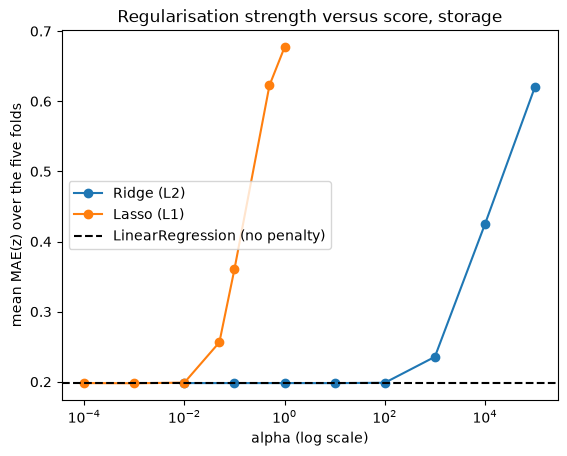

In [27]:
plt.plot(ridge_alphas, ridge_scores, marker="o", label="Ridge (L2)")
plt.plot(lasso_alphas, lasso_scores, marker="o", label="Lasso (L1)")
plt.axhline(ols_mean, color="black", linestyle="--", label="LinearRegression (no penalty)")
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("mean MAE(z) over the five folds")
plt.title("Regularisation strength versus score, storage")
plt.legend()
plt.show()

In [28]:
train_idx, val_idx = folds[0]
prep = make_preprocessor()
X_train_prep = prep.fit_transform(X.iloc[train_idx])
print("Shape:", X_train_prep.shape)
print("Rank:", np.linalg.matrix_rank(X_train_prep))
print("Condition number:", round(np.linalg.cond(X_train_prep), 2))
print("Configurations in training:", groups["config_group"].iloc[train_idx].nunique())
print("Configurations in total:", groups["config_group"].nunique())

Shape: (9750, 13)
Rank: 13
Condition number: 8.17
Configurations in training: 1950
Configurations in total: 2438


**Comparison with the unregularised model.** 
The unregularised LinearRegression has a mean MAE(z) of 0.1981. The best Ridge value tried (alpha = 10) gives 0.1981 and the best Lasso value tried (alpha = 0.001) gives 0.1979. That Lasso gain of about 0.0003 is small beside the fold-to-fold range (max − min) of 0.0111 and was picked on the same folds, so it is slightly optimistic. Stronger penalties only make the model worse, slightly at Ridge alpha = 100 and Lasso alpha = 0.01, and clearly from Ridge alpha = 1000 and Lasso alpha = 0.05. Under Lasso, the coefficients driven to exactly zero go from 0 of 13 at alpha = 0.0001 to 5 at alpha = 0.01 and all 13 at alpha = 1, where the model predicts a constant.




**Recommendation, from the shape of the problem.** 
We recommend keeping the unregularised model. The design matrix is narrow relative to the sample: 13 columns against 9,750 training rows in fold 0. Those rows come from only about 1,950 distinct configurations (2,438 across the development table), which is still far more than 13. The matrix has full rank (13) and a low condition number (8.17), so the predictors are not severely collinear and the coefficients are already stable. A penalty has little variance to remove here. The remaining error is more likely bias from the linear form, which a penalty cannot fix.


# P3.5 — Challenge B against Practice 2

## Paired comparison against Practice 2

**The Practice 3 row of Challenge B.** Every value is copied from the saved outputs of R3's
notebook (P3.3). The row is the unregularised `LinearRegression`, the model recommended in
P3.4. As in Challenge A, the cell checks the copied mean and spread before adding the row.

In [29]:
# Practice 3 row of Challenge B, copied from the saved outputs of R3's notebook
storage_row = {
    "milestone": "P3",
    "challenge": "storage",
    "family": "LinearRegression",
    "route": "primary",
    "configuration": "ordinary least squares, no penalty; no hyperparameter search "
                     "(Ridge and Lasso compared in P3.4)",
    "preprocessing": "one-hot on the 4 nominal predictors with one reference level dropped "
                     "(load_type=random, io_type=write, raid=4+1, device_type=nvme), unseen "
                     "level encoded as the reference; StandardScaler on the 5 numeric ones; "
                     "fitted inside each fold; target z = log10(latency_ns)",
    "features": "features.md: the 9 distributed source predictors (frozen basis)",
    "validation": "canonical GroupKFold(5) on config_group, read from folds/storage_folds.csv",
    "primary_metric_per_fold": "0.2047 0.1937 0.1984 0.1953 0.1987",
    "primary_metric": 0.1981,
    "primary_metric_spread": 0.0110,
    "supporting_metrics": "RMSE(z) 0.2703; R2(z) 0.8964; MAE_ns 16289769 "
                          "(computed after inverting predictions)",
    "fit_time_s": 0.0298,   # mean fit time per fold printed by R3's notebook (approximate)
    "interpretability": "each coefficient is a factor 10^coef on latency: per standard "
                        "deviation of a numeric predictor, or per level against its reference",
    "notes": "additive model on z; worse than KNN on every fold; Ridge and Lasso gave "
             "no meaningful gain over it (P3.4); fit time is approximate and changes "
             "between runs",
}

# Check against typing mistakes: mean and spread must agree with the five fold values
copied_folds = np.array(storage_row["primary_metric_per_fold"].split(), dtype=float)
mean_check, spread_check = mean_and_spread(copied_folds)
assert abs(mean_check - storage_row["primary_metric"]) < 0.0001
assert abs(spread_check - storage_row["primary_metric_spread"]) < 0.00001

# Add the row at the end of comparativa.csv (the Practice 2 rows are not touched)
append_comparativa_row(storage_row)

added to comparativa.csv: P3 storage LinearRegression


In [30]:
# Paired differences, both rows read from comparativa.csv
new_scores = table_scores("P3", "storage", "LinearRegression")
old_scores = table_scores("P2", "storage", "KNN")

# delta = P2 - P3 for MAE(z), so a positive value means the linear model did better
storage_deltas = paired_differences("storage", new_scores, old_scores)

          P2     new   delta
fold                        
1     0.1816  0.2047 -0.0231
2     0.1870  0.1937 -0.0067
3     0.1778  0.1984 -0.0206
4     0.1775  0.1953 -0.0178
5     0.1762  0.1987 -0.0225
mean delta            -0.0181
spread of delta       0.0164   (max - min)
folds with delta > 0  0 of 5
spread of P2 row      0.0108
spread of new row     0.0110


**Reading of the differences, and which kind of comparison this is.** The linear regression
has a higher MAE(z) than the Practice 2 KNN on all five folds, so every difference is
negative. The mean difference is −0.0181. The size changes more from fold to fold than in
Challenge A: from −0.0231 to −0.0067 (spread 0.0164), against a fold-to-fold spread of about
0.011 for each of the two rows. So the direction is the same on every fold, but the size is
less stable. This describes these five folds; it is not a statistical test.

As in Challenge A, Practice 2 one-hot encodes every level and Practice 3 drops one reference
level per nominal predictor, so this is a **pipeline comparison**, not an isolated
comparison of model families.

In [31]:
#here we're comparing the lineal regression model against the KNN on each fold
#Practice 2 KNN (k=20), MAE(z) per fold, from comparativa.csv
p2_scores = np.array([0.1816, 0.1870, 0.1778, 0.1775, 0.1762])
new_scores = np.array(mae_list)

# positive means the new model did better on that fold
deltas = p2_scores - new_scores

print("P2 KNN:", p2_scores)
print("P3 linear:", np.round(new_scores, 4))
print("Deltas:", np.round(deltas, 4))
print("Mean delta:", round(np.mean(deltas), 4))
print("Range of deltas (max - min):", round(np.max(deltas) - np.min(deltas), 4))
print("Range of P2 scores:", round(np.max(p2_scores) - np.min(p2_scores), 4))
print("Range of new scores:", round(np.max(new_scores) - np.min(new_scores), 4))

P2 KNN: [0.1816 0.187  0.1778 0.1775 0.1762]
P3 linear: [0.2047 0.1937 0.1984 0.1953 0.1987]
Deltas: [-0.0231 -0.0067 -0.0206 -0.0178 -0.0225]
Mean delta: -0.0181
Range of deltas (max - min): 0.0165
Range of P2 scores: 0.0108
Range of new scores: 0.0111


### Why the ordering came out this way

KNN (k = 20) beats LinearRegression on MAE(z) on all five folds. The linear model on z assumes that each predictor adds a fixed amount to z, whatever the other predictors are, while KNN averages similar configurations and so can follow interactions. For example, the effect of iodepth could differ between hdd and nvme. This is our most likely explanation, but we did not test it. KNN’s k was also selected on these same folds, which slightly favours it.

### The six fixed comparison questions

1. **Size and consistency of the change.** Using the five paired differences (descriptive only).

The mean paired difference is −0.0181 in MAE(z), about 10% of the Practice 2 score. The sign is the same on all five folds (−0.0231, −0.0067, −0.0206, −0.0178, −0.0225), so KNN was better on each. The size varies: the deltas have a range (max − min) of 0.0165. Relative to the fold-to-fold range of either model (about 0.011), the change is large. This is only a description of these five folds, not a significance test, and it does not establish that the difference would hold on new data.




2. **Route and representation.** Pipeline comparison or isolated family comparison, and what the evidence licenses. 

Both rows are on the primary route, but they do not use the same representation: Practice 2 kept every one-hot level, while Practice 3 drops one declared reference level per predictor. The numeric scaling is the same. This is therefore a pipeline comparison, not an isolated family comparison. The evidence supports saying this pipeline did better than that one on these folds. It does not establish that the family alone caused the difference.




3. **What can the new family express** that the previous one could not? 

The linear model gives one global, additive equation. Each coefficient has a direct reading: a multiplicative factor on latency per standard deviation of a numeric predictor, or per level against its declared reference. KNN gives no such summary. In exchange, without added interaction terms the linear model cannot express effects that depend on another predictor, which KNN can follow.






4. **What did it cost** in fitting time, tuning effort and interpretability? 


Fitting time is small for both: a few hundredths of a second per fold (printed above), against about 0.01 s for KNN. The exact value changes from machine to machine, so only the order of magnitude matters. LinearRegression needs no hyperparameter search, while KNN searched 11 values of k. Ridge and Lasso did add tuning, and it brought almost no improvement. Interpretability improved, but the accuracy on z fell.




5. **Did the ordering of the two challenges' difficulty change**, and why? 

Challenge A (R2): logistic regression gets a mean macro F1 of 0.8381 against 0.9456 for KNN, worse on all five folds. Since the metrics differ, we compare each challenge with its own Dummy. In cyber, KNN closes 94% of the gap to a perfect score and logistic regression 83%. In storage, KNN cuts the Dummy's MAE(z) by 73% and LinearRegression by 71%. The ordering did not change, but the linear model lost much more in cyber (about 11 points against 3). Our untested explanation: some cyber classes overlap in ways a linear boundary cannot separate, while z is close to additive.




6. **Would you ship the new model?** If not, what would change your mind?

Not as a replacement if the goal is the lowest error on z, because KNN was better on all five folds. We would use the linear model when the goal is to explain latency, because it gives readable factors. The picture is not one-sided: on MAE in nanoseconds the linear model is lower (about 16.3 million against 17.2 million), although RMSE(z) and R²(z) favour KNN (0.2703 and 0.8964 against 0.2568 and 0.9065). We would change our mind if interaction terms closed the gap on z, or if the error on the slowest configurations in nanoseconds mattered most.




# Comparison table

The Practice 3 rows are added in the paired-comparison part of each challenge, just before
their differences are computed, because the differences are read from the table. This last
cell shows the whole table so that we can check that the four Practice 2 rows are still the
first rows, unchanged, and that the new rows come after them.

Practice 2 and Practice 3 do not use the same representation of the nominal predictors:
Practice 2 one-hot encodes every level, Practice 3 drops one reference level per predictor.
The information basis is the same (the same source predictors, no derived feature), but the
representation is not, so every Practice 3 against Practice 2 difference is a **pipeline
comparison**, not an isolated comparison of model families.

In [32]:
# Read the whole table and show its main columns
table = pd.read_csv(COMPARISON_PATH)
print(table[["milestone", "challenge", "family", "route",
             "primary_metric", "primary_metric_spread"]].to_string())

# The table is only appended to: the Practice 2 rows are still the first four rows
assert list(table["milestone"].iloc[:4]) == ["P2", "P2", "P2", "P2"]

  milestone challenge            family    route  primary_metric  primary_metric_spread
0        P2     cyber             Dummy  primary          0.0242                 0.0000
1        P2   storage             Dummy  primary          0.6770                 0.0294
2        P2     cyber               KNN  primary          0.9456                 0.0062
3        P2   storage               KNN  primary          0.1800                 0.0109
4        P3   storage  LinearRegression  primary          0.1981                 0.0110
